# Notebook 05 — Model Optimization & Hyperparameter Tuning

## Objectif

Optimiser le modèle **SVM** pour la prédiction du *Churn* avec `RandomizedSearchCV`.

### Étapes
1. Installer et importer les dépendances.
2. Localiser le projet et charger les données prétraitées.
3. Vérifier les dimensions, les colonnes et les valeurs manquantes.
4. Charger et évaluer le modèle SVM initial.
5. Chercher les meilleurs hyperparamètres avec une validation croisée stratifiée.
6. Évaluer et comparer les modèles initial et optimisé sur le jeu de test.
7. Sauvegarder le modèle optimisé et les rapports.

**Règle anti-fuite de données :** la recherche d'hyperparamètres utilise uniquement `X_train` et `y_train`. Le jeu de test est réservé à l'évaluation finale.

In [55]:
%pip install -q pandas numpy matplotlib scipy scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [56]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy.stats import loguniform

from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
N_ITER = 20
CV_SPLITS = 5

print("Scikit-learn :", sklearn.__version__)
print("Bibliothèques importées avec succès.")

Scikit-learn : 1.9.1
Bibliothèques importées avec succès.


## 1. Localisation du projet

Le notebook accepte les deux organisations suivantes :

- **Projet organisé :** `data/processed/`, `models/`, `reports/`.
- **Fichiers placés à côté du notebook :** les CSV et le modèle sont dans le même dossier.

Dans les deux cas, les dossiers de sortie sont créés automatiquement.

In [57]:
CURRENT_DIR = Path.cwd().resolve()

# Chercher le dossier du projet dans le dossier courant et ses parents.
PROJECT_DIR = None
for candidate in [CURRENT_DIR, *CURRENT_DIR.parents]:
    if (candidate / "data" / "processed").is_dir():
        PROJECT_DIR = candidate
        DATA_DIR = candidate / "data" / "processed"
        break

# Mode de secours : fichiers CSV placés directement dans le dossier courant.
if PROJECT_DIR is None:
    required_files = [
        "X_train_processed.csv", "X_test_processed.csv",
        "y_train.csv", "y_test.csv",
    ]
    if all((CURRENT_DIR / name).is_file() for name in required_files):
        PROJECT_DIR = CURRENT_DIR
        DATA_DIR = CURRENT_DIR
    else:
        raise FileNotFoundError(
            "Données introuvables. Placez les CSV dans data/processed/ "
            "ou dans le même dossier que le notebook."
        )

MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Dossier du projet :", PROJECT_DIR)
print("Dossier des données :", DATA_DIR)
print("Dossier des modèles :", MODELS_DIR)
print("Dossier des rapports :", REPORTS_DIR)

Dossier du projet : C:\Users\Octinz\Documents\automl-mlops-platform
Dossier des données : C:\Users\Octinz\Documents\automl-mlops-platform\data\processed
Dossier des modèles : C:\Users\Octinz\Documents\automl-mlops-platform\models
Dossier des rapports : C:\Users\Octinz\Documents\automl-mlops-platform\reports


## 2. Chargement des données prétraitées

In [58]:
X_train = pd.read_csv(DATA_DIR / "X_train_processed.csv")
X_test = pd.read_csv(DATA_DIR / "X_test_processed.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze("columns")
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze("columns")

# Les classes du projet sont encodées en 0 (No Churn) et 1 (Churn).
y_train = pd.to_numeric(y_train, errors="raise").astype(int)
y_test = pd.to_numeric(y_test, errors="raise").astype(int)

print("Données chargées avec succès.")
print("\nDimensions :")
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

print("\nDistribution de y_train :")
display(y_train.value_counts().sort_index().rename("Effectif").to_frame())
print("\nDistribution de y_test :")
display(y_test.value_counts().sort_index().rename("Effectif").to_frame())

Données chargées avec succès.

Dimensions :
X_train : (5634, 45)
X_test  : (1409, 45)
y_train : (5634,)
y_test  : (1409,)

Distribution de y_train :


,Effectif
Churn,
0,4139
1,1495



Distribution de y_test :


,Effectif
Churn,
0,1035
1,374


## 3. Vérification des données

In [59]:
assert len(X_train) == len(y_train), "Train : X et y n'ont pas le même nombre de lignes."
assert len(X_test) == len(y_test), "Test : X et y n'ont pas le même nombre de lignes."
assert list(X_train.columns) == list(X_test.columns), "Les colonnes Train et Test diffèrent."
assert X_train.columns.is_unique, "Les noms de colonnes de X_train ne sont pas uniques."
assert not X_train.isnull().any().any(), "X_train contient des valeurs manquantes."
assert not X_test.isnull().any().any(), "X_test contient des valeurs manquantes."
assert set(pd.unique(y_train)).issubset({0, 1}), "y_train doit contenir uniquement 0 et 1."
assert set(pd.unique(y_test)).issubset({0, 1}), "y_test doit contenir uniquement 0 et 1."
assert y_train.nunique() == 2 and y_test.nunique() == 2, "Les deux classes doivent être présentes."

# Les SVM scikit-learn attendent ici des variables numériques.
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_train.dtypes), (
    "Certaines colonnes ne sont pas numériques. Vérifiez le prétraitement."
)

print("Vérifications terminées : les données sont cohérentes.")

Vérifications terminées : les données sont cohérentes.


## 4. Chargement du modèle SVM initial

Le fichier prioritaire est `models/best_model_evaluated.joblib`. Si les fichiers sont placés directement à côté du notebook, le notebook cherche également `best_model_evaluated.joblib`.

Un modèle SVM sauvegardé sous le nom `svm.joblib` est accepté comme solution de secours.

In [60]:
model_candidates = [
    MODELS_DIR / "best_model_evaluated.joblib",
    PROJECT_DIR / "best_model_evaluated.joblib",
    MODELS_DIR / "svm.joblib",
    PROJECT_DIR / "svm.joblib",
]
initial_model_path = next((path for path in model_candidates if path.is_file()), None)

if initial_model_path is None:
    raise FileNotFoundError(
        "Modèle SVM introuvable. Attendu : models/best_model_evaluated.joblib "
        "ou best_model_evaluated.joblib à côté du notebook."
    )

# joblib/pickle doit être chargé uniquement si le fichier provient d'une source fiable.
initial_model = joblib.load(initial_model_path)

if not isinstance(initial_model, SVC):
    raise TypeError(
        f"Le modèle chargé est {type(initial_model).__name__}, alors qu'un SVC est attendu."
    )

print("Modèle initial chargé :", initial_model_path)
print("Type :", type(initial_model).__name__)
print("Paramètres :")
print(initial_model.get_params())

Modèle initial chargé : C:\Users\Octinz\Documents\automl-mlops-platform\models\best_model_evaluated.joblib
Type : SVC
Paramètres :
{'C': 1.0, 'break_ties': False, 'cache_size': 200, 'class_weight': 'balanced', 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'probability': True, 'random_state': 42, 'shrinking': True, 'tol': 0.001, 'verbose': False}


## 5. Fonction d'évaluation

Les métriques sont calculées pour la classe positive `1` (*Churn*). Pour ROC-AUC et Average Precision, le notebook utilise les probabilités si elles sont disponibles, sinon le score de décision du modèle.

In [61]:
def evaluate_model(model, X, y, model_name):
    y_pred = model.predict(X)

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X)[:, 1]
    elif hasattr(model, "decision_function"):
        scores = model.decision_function(X)
    else:
        scores = None

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y, y_pred),
        "Precision": precision_score(y, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y, y_pred, pos_label=1, zero_division=0),
        "F1": f1_score(y, y_pred, pos_label=1, zero_division=0),
    }

    if scores is not None and pd.Series(y).nunique() == 2:
        results["ROC-AUC"] = roc_auc_score(y, scores)
        results["Average Precision"] = average_precision_score(y, scores)
    else:
        results["ROC-AUC"] = np.nan
        results["Average Precision"] = np.nan

    return results, y_pred


initial_results, y_pred_initial = evaluate_model(
    initial_model, X_test, y_test, "SVM Initial"
)
initial_results_df = pd.DataFrame([initial_results])

print("Évaluation du modèle SVM initial sur le jeu de test :")
display(initial_results_df.round(4))

Évaluation du modèle SVM initial sur le jeu de test :


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,SVM Initial,0.7438,0.5115,0.7727,0.6155,0.821,0.5914


## 6. Définition de la recherche d'hyperparamètres

Paramètres étudiés :
- `C` : régularisation du SVM.
- `gamma` : influence d'un exemple pour le noyau RBF (sans effet pour le noyau linéaire).
- `kernel` : noyau `rbf` ou `linear`.

Le score choisi pour sélectionner les paramètres est le **F1-score**, afin de tenir compte à la fois de la précision et du rappel de la classe *Churn*.

In [62]:
param_distributions = {
    "C": loguniform(0.01, 100),
    "gamma": loguniform(0.0001, 1),
    "kernel": ["rbf", "linear"],
}

cv_strategy = StratifiedKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

svm_model = SVC(
    class_weight="balanced",
    probability=False,  # decision_function suffit pour ROC-AUC et Average Precision.
    random_state=RANDOM_STATE,
)

print("Espace de recherche :")
print("C : log-uniforme entre 0.01 et 100")
print("gamma : log-uniforme entre 0.0001 et 1")
print("kernel :", param_distributions["kernel"])
print(f"Validation croisée : {CV_SPLITS} folds stratifiés")

Espace de recherche :
C : log-uniforme entre 0.01 et 100
gamma : log-uniforme entre 0.0001 et 1
kernel : ['rbf', 'linear']
Validation croisée : 5 folds stratifiés


## 7. Optimisation avec RandomizedSearchCV

La recherche est entraînée **uniquement sur le jeu Train**. Avec 20 combinaisons et 5 folds, 100 ajustements sont réalisés. Cela peut prendre quelques minutes selon l'ordinateur.

In [63]:

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.svm import SVC

import pandas as pd
import numpy as np
import joblib

RANDOM_STATE = 42

print("Imports réussis !")

Imports réussis !


In [64]:
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import loguniform

RANDOM_STATE = 42

# Nombre de recherches
N_ITER = 8
CV_SPLITS = 3

# Espace de recherche
param_distributions = {
    "C": loguniform(0.01, 100),
    "gamma": loguniform(0.0001, 1),
    "kernel": ["rbf", "linear"]
}

# Modèle SVM initial pour l'optimisation
svm_model = SVC(
    class_weight="balanced",
    probability=False,
    random_state=RANDOM_STATE
)

# Validation croisée
cv_strategy = StratifiedKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("SVM model défini avec succès !")
print("Paramètres :", svm_model.get_params())

SVM model défini avec succès !
Paramètres : {'C': 1.0, 'break_ties': False, 'cache_size': 200, 'class_weight': 'balanced', 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'probability': False, 'random_state': 42, 'shrinking': True, 'tol': 0.001, 'verbose': False}


In [65]:
import pandas as pd
from pathlib import Path

# Chemin du projet
PROJECT_DIR = Path(r"C:\Users\Octinz\Documents\automl-mlops-platform")
DATA_DIR = PROJECT_DIR / "data" / "processed"

# Chargement des données
X_train = pd.read_csv(DATA_DIR / "X_train_processed.csv")
X_test = pd.read_csv(DATA_DIR / "X_test_processed.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze("columns")
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze("columns")

# Conversion des targets
y_train = pd.to_numeric(y_train).astype(int)
y_test = pd.to_numeric(y_test).astype(int)

print("Données chargées avec succès !")
print("X_train :", X_train.shape)
print("y_train :", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

Données chargées avec succès !
X_train : (5634, 45)
y_train : (5634,)
X_test : (1409, 45)
y_test : (1409,)


In [67]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from scipy.stats import loguniform

# 1. Réduire la taille pour accélérer la recherche
X_search, _, y_search, _ = train_test_split(
    X_train,
    y_train,
    train_size=2500,
    stratify=y_train,
    random_state=42
)

# 2. Définir les paramètres
param_distributions = {
    "C": loguniform(0.01, 100),
    "gamma": loguniform(0.0001, 1),
    "kernel": ["rbf", "linear"]
}

# 3. Modèle SVM
svm_model = SVC(
    class_weight="balanced",
    probability=False,
    random_state=42,
    cache_size=1000
)

# 4. Cross Validation
cv_strategy = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

# 5. Randomized Search
random_search = RandomizedSearchCV(
    estimator=svm_model,
    param_distributions=param_distributions,
    n_iter=4,
    cv=cv_strategy,
    scoring="f1",
    n_jobs=1,
    verbose=2,
    random_state=42,
    refit=False
)

print("Début de l'optimisation SVM...")
print("Nombre total d'entraînements : 8")

random_search.fit(X_search, y_search)

print("\nOptimisation terminée !")
print("Meilleurs paramètres :", random_search.best_params_)
print("Meilleur F1 CV :", random_search.best_score_)

Début de l'optimisation SVM...
Nombre total d'entraînements : 8
Fitting 2 folds for each of 4 candidates, totalling 8 fits


C:\Users\Octinz\Documents\automl-mlops-platform\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


[CV] END C=0.31489116479568624, gamma=0.6351221010640696, kernel=rbf; total time=   1.2s


C:\Users\Octinz\Documents\automl-mlops-platform\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


[CV] END C=0.31489116479568624, gamma=0.6351221010640696, kernel=rbf; total time=   1.1s


C:\Users\Octinz\Documents\automl-mlops-platform\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


... (7 outputs left out)

C:\Users\Octinz\Documents\automl-mlops-platform\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


[CV] END C=0.21618942406574443, gamma=0.0003727925903376988, kernel=rbf; total time=   0.9s


C:\Users\Octinz\Documents\automl-mlops-platform\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


[CV] END C=0.21618942406574443, gamma=0.0003727925903376988, kernel=rbf; total time=   0.8s

Optimisation terminée !
Meilleurs paramètres : {'C': np.float64(0.042070539502879395), 'gamma': np.float64(0.0001707396743152812), 'kernel': 'linear'}
Meilleur F1 CV : 0.6068343879922499


In [68]:
best_params = random_search.best_params_

print("Meilleurs hyperparamètres :")
print(best_params)
print("\nMeilleur F1-score moyen en validation croisée :")
print(f"{random_search.best_score_:.4f}")

Meilleurs hyperparamètres :
{'C': np.float64(0.042070539502879395), 'gamma': np.float64(0.0001707396743152812), 'kernel': 'linear'}

Meilleur F1-score moyen en validation croisée :
0.6068


In [70]:
search_results = pd.DataFrame(random_search.cv_results_)

columns_to_show = [
    "params",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

search_results = search_results[columns_to_show]

search_results = search_results.sort_values(
    by="rank_test_score"
)

display(search_results)

,params,mean_test_score,std_test_score,rank_test_score
2,"{'C': 0.042070539502879395, 'gamma': 0.0001707...",0.606834,0.025337,1
1,"{'C': 13.145103232150124, 'gamma': 0.024400607...",0.602156,0.030727,2
0,"{'C': 0.31489116479568624, 'gamma': 0.63512210...",0.466733,0.030584,3
3,"{'C': 0.21618942406574443, 'gamma': 0.00037279...",0.023529,0.023529,4


In [71]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.svm import SVC

import pandas as pd
import numpy as np
import joblib

RANDOM_STATE = 42

print("Imports réussis !")

Imports réussis !


In [72]:
import matplotlib.pyplot as plt

print("Matplotlib importé avec succès !")

Matplotlib importé avec succès !


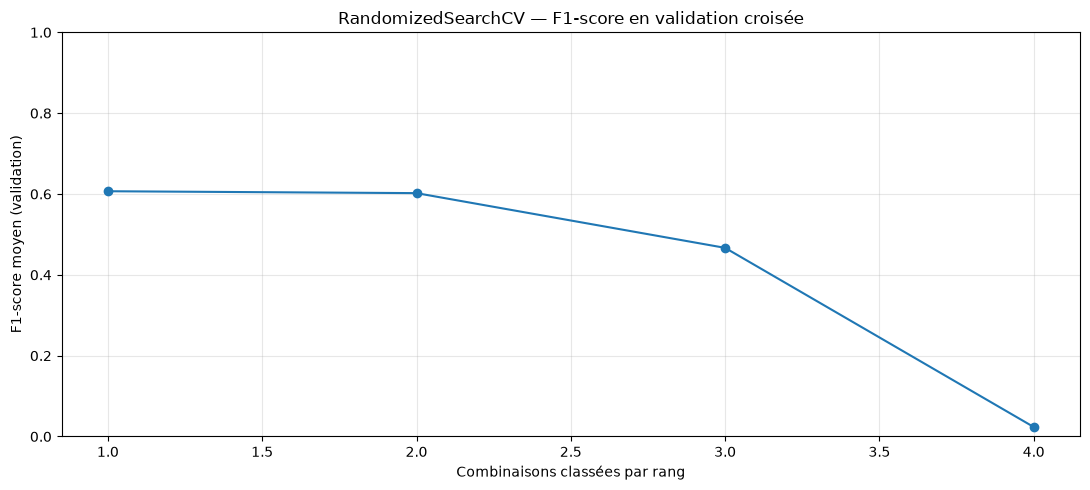

In [73]:
plt.figure(figsize=(11, 5))
plt.plot(
    np.arange(1, len(search_results) + 1),
    search_results["mean_test_score"],
    marker="o",
)
plt.title("RandomizedSearchCV — F1-score en validation croisée")
plt.xlabel("Combinaisons classées par rang")
plt.ylabel("F1-score moyen (validation)")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

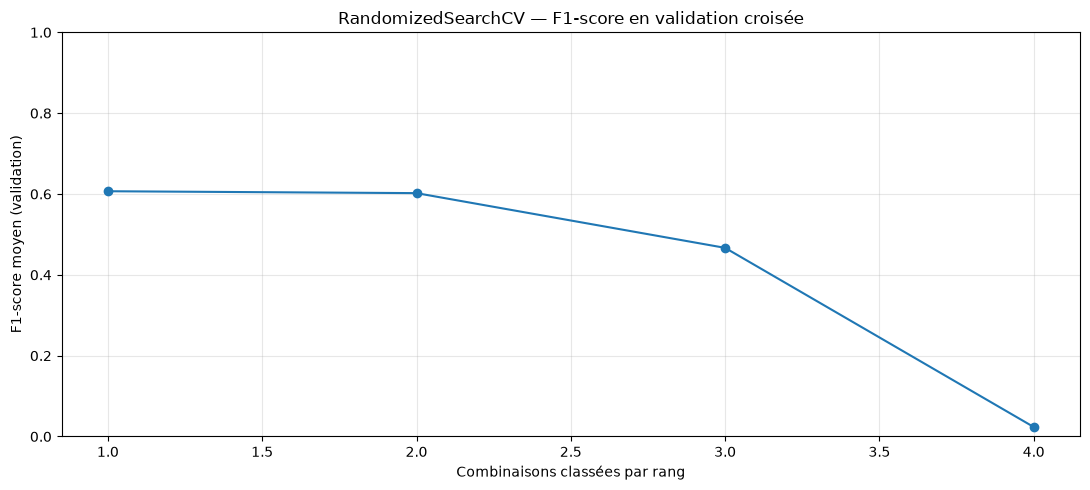

In [74]:
plt.figure(figsize=(11, 5))
plt.plot(
    np.arange(1, len(search_results) + 1),
    search_results["mean_test_score"],
    marker="o",
)
plt.title("RandomizedSearchCV — F1-score en validation croisée")
plt.xlabel("Combinaisons classées par rang")
plt.ylabel("F1-score moyen (validation)")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

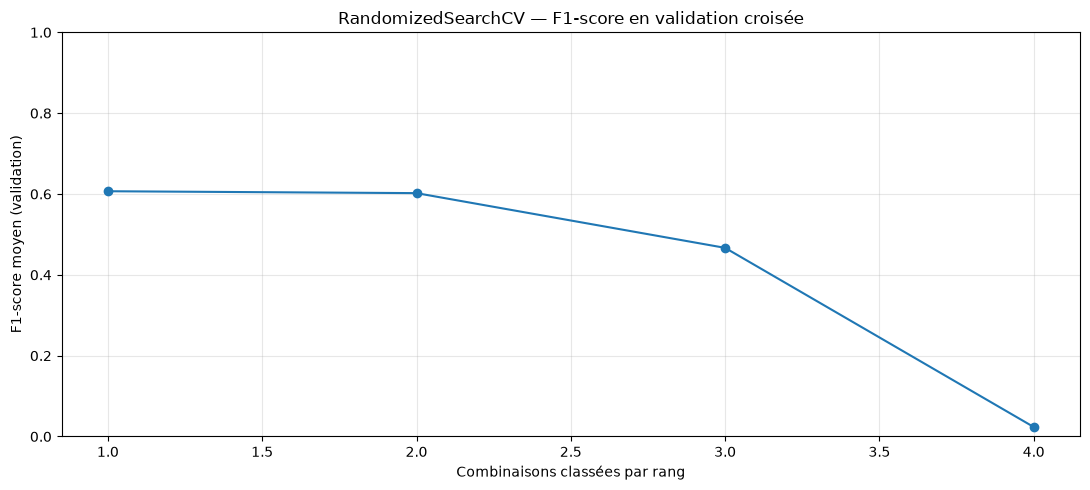

In [75]:
plt.figure(figsize=(11, 5))
plt.plot(
    np.arange(1, len(search_results) + 1),
    search_results["mean_test_score"],
    marker="o",
)
plt.title("RandomizedSearchCV — F1-score en validation croisée")
plt.xlabel("Combinaisons classées par rang")
plt.ylabel("F1-score moyen (validation)")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

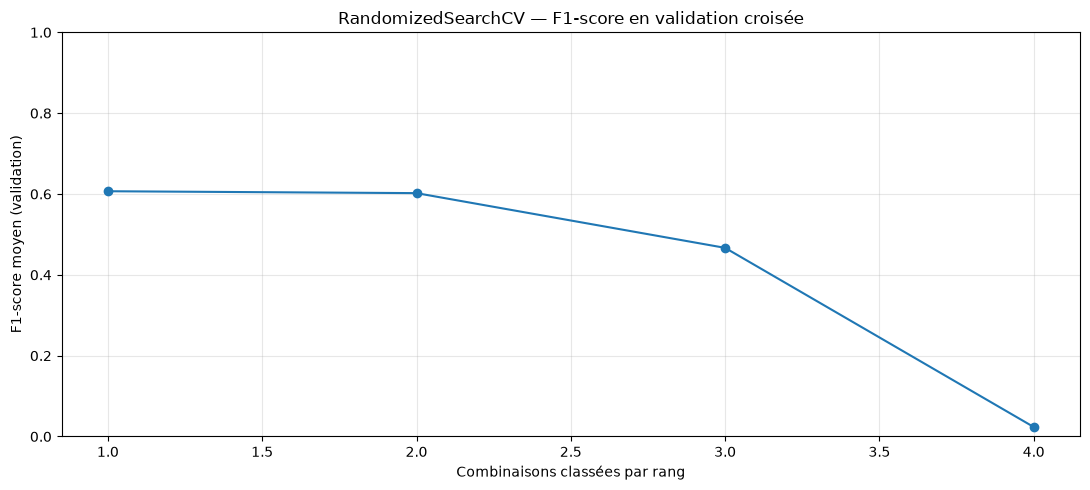

In [76]:
plt.figure(figsize=(11, 5))
plt.plot(
    np.arange(1, len(search_results) + 1),
    search_results["mean_test_score"],
    marker="o",
)
plt.title("RandomizedSearchCV — F1-score en validation croisée")
plt.xlabel("Combinaisons classées par rang")
plt.ylabel("F1-score moyen (validation)")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Modèle optimisé

`RandomizedSearchCV` a déjà réentraîné automatiquement (`refit=True`) le meilleur estimateur sur **tout le jeu Train**. On réutilise donc directement `best_estimator_` : cela évite un deuxième entraînement inutile.

In [79]:
from sklearn.svm import SVC

# Récupérer les meilleurs paramètres
best_params = random_search.best_params_

print("Meilleurs paramètres :")
print(best_params)

# Créer le modèle optimisé
optimized_model = SVC(
    **best_params,
    class_weight="balanced",
    probability=False,
    random_state=42,
    cache_size=1000
)

# Entraîner sur toutes les données d'entraînement
optimized_model.fit(X_train, y_train)

print("\nMeilleur modèle SVM entraîné sur toutes les données !")

Meilleurs paramètres :
{'C': np.float64(0.042070539502879395), 'gamma': np.float64(0.0001707396743152812), 'kernel': 'linear'}


C:\Users\Octinz\Documents\automl-mlops-platform\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Meilleur modèle SVM entraîné sur toutes les données !


In [81]:
print("Modèle entraîné :", hasattr(optimized_model, "support_vectors_"))

print("Nombre de Support Vectors :",
      len(optimized_model.support_vectors_))

print("Shape X_test :", X_test.shape)

Modèle entraîné : True
Nombre de Support Vectors : 3188
Shape X_test : (1409, 45)


In [82]:
optimized_results, y_pred_optimized = evaluate_model(
    optimized_model, X_test, y_test, "SVM Optimisé"
)

print("Évaluation du modèle SVM optimisé sur le jeu de test :")
display(pd.DataFrame([optimized_results]).round(4))

Évaluation du modèle SVM optimisé sur le jeu de test :


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,SVM Optimisé,0.6941,0.4575,0.8209,0.5876,0.835,0.6358


In [83]:
optimized_results, y_pred_optimized = evaluate_model(
    optimized_model, X_test, y_test, "SVM Optimisé"
)

print("Évaluation du modèle SVM optimisé sur le jeu de test :")
display(pd.DataFrame([optimized_results]).round(4))

Évaluation du modèle SVM optimisé sur le jeu de test :


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,SVM Optimisé,0.6941,0.4575,0.8209,0.5876,0.835,0.6358


In [84]:
optimized_results, y_pred_optimized = evaluate_model(
    optimized_model, X_test, y_test, "SVM Optimisé"
)

print("Évaluation du modèle SVM optimisé sur le jeu de test :")
display(pd.DataFrame([optimized_results]).round(4))

Évaluation du modèle SVM optimisé sur le jeu de test :


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,SVM Optimisé,0.6941,0.4575,0.8209,0.5876,0.835,0.6358


## 9. Comparaison des performances sur le jeu de test

In [85]:
comparison_df = pd.DataFrame([initial_results, optimized_results])

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "Average Precision",
]

print("Comparaison SVM initial vs SVM optimisé :")
display(comparison_df.set_index("Model")[metrics].round(4))

Comparaison SVM initial vs SVM optimisé :


,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Model,,,,,,
SVM Initial,0.7438,0.5115,0.7727,0.6155,0.821,0.5914
SVM Optimisé,0.6941,0.4575,0.8209,0.5876,0.835,0.6358


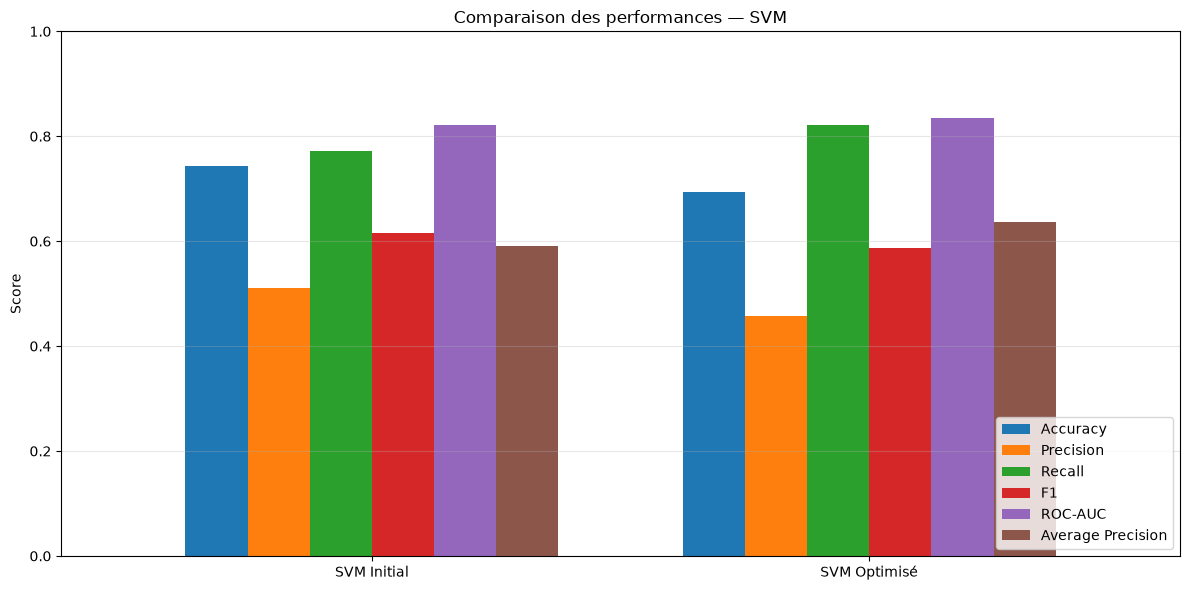

In [86]:
ax = comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.75,
)
ax.set_title("Comparaison des performances — SVM")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10. Matrices de confusion

Les matrices montrent les prédictions correctes et les erreurs pour chaque classe : `0 = No Churn`, `1 = Churn`.

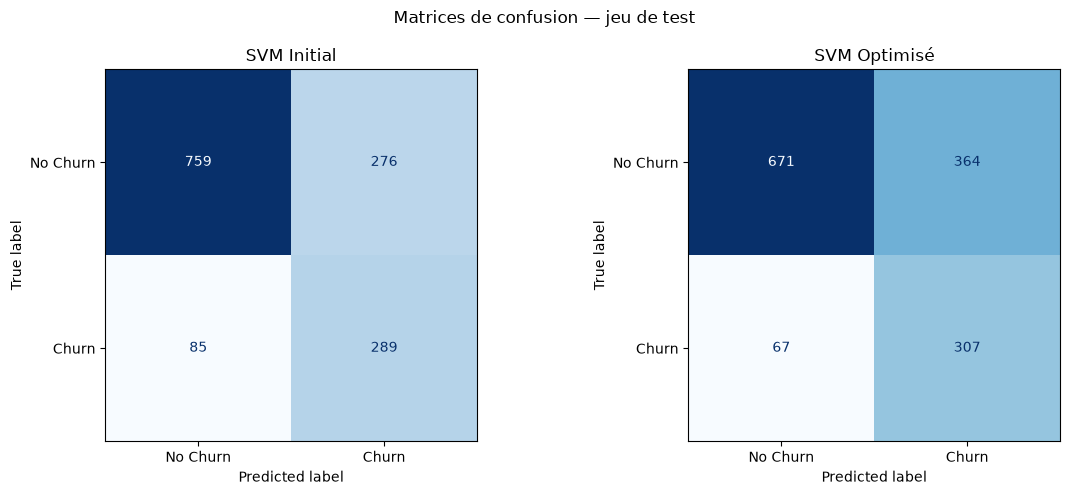

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_pred, title in [
    (axes[0], y_pred_initial, "SVM Initial"),
    (axes[1], y_pred_optimized, "SVM Optimisé"),
]:
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"],
    ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)

plt.suptitle("Matrices de confusion — jeu de test")
plt.tight_layout()
plt.show()

## 11. Rapport de classification du modèle optimisé

In [88]:
optimized_report = classification_report(
    y_test,
    y_pred_optimized,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0,
    output_dict=True,
)

print(classification_report(
    y_test,
    y_pred_optimized,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0,
))

              precision    recall  f1-score   support

    No Churn       0.91      0.65      0.76      1035
       Churn       0.46      0.82      0.59       374

    accuracy                           0.69      1409
   macro avg       0.68      0.73      0.67      1409
weighted avg       0.79      0.69      0.71      1409



## 12. Sauvegarde du modèle et des rapports

In [89]:
optimized_model_path = MODELS_DIR / "best_model_optimized.joblib"
joblib.dump(optimized_model, optimized_model_path)

search_report_path = REPORTS_DIR / "svm_hyperparameter_search.csv"
search_results.to_csv(search_report_path, index=False)

comparison_report_path = REPORTS_DIR / "svm_optimization_comparison.csv"
comparison_df.to_csv(comparison_report_path, index=False)

best_params_path = REPORTS_DIR / "svm_best_hyperparameters.json"
with open(best_params_path, "w", encoding="utf-8") as file:
    json.dump(best_params, file, indent=4)

classification_report_path = REPORTS_DIR / "svm_optimized_classification_report.json"
with open(classification_report_path, "w", encoding="utf-8") as file:
    json.dump(optimized_report, file, indent=4)

print("Fichiers sauvegardés :")
for path in [
    optimized_model_path,
    search_report_path,
    comparison_report_path,
    best_params_path,
    classification_report_path,
]:
    print(f"- {path} | existe : {path.is_file()}")

Fichiers sauvegardés :
- C:\Users\Octinz\Documents\automl-mlops-platform\models\best_model_optimized.joblib | existe : True
- C:\Users\Octinz\Documents\automl-mlops-platform\reports\svm_hyperparameter_search.csv | existe : True
- C:\Users\Octinz\Documents\automl-mlops-platform\reports\svm_optimization_comparison.csv | existe : True
- C:\Users\Octinz\Documents\automl-mlops-platform\reports\svm_best_hyperparameters.json | existe : True
- C:\Users\Octinz\Documents\automl-mlops-platform\reports\svm_optimized_classification_report.json | existe : True


In [90]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    optimized_model,
    "models/svm_optimized_candidate.joblib"
)

print("SVM Optimisé sauvegardé avec succès !")
print("Fichier : models/svm_optimized_candidate.joblib")

SVM Optimisé sauvegardé avec succès !
Fichier : models/svm_optimized_candidate.joblib


In [92]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models_to_compare = {
    "SVM Original": initial_model,
    "SVM Optimisé": optimized_model
}

comparison = []

for name, model in models_to_compare.items():

    predictions = model.predict(X_test)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,SVM Original,0.7438,0.5115,0.7727,0.6155
1,SVM Optimisé,0.6941,0.4575,0.8209,0.5876


## 13. Conclusion

Dans ce notebook, le modèle SVM initial est comparé à un SVM optimisé par `RandomizedSearchCV`.

- La recherche des hyperparamètres est effectuée sur le jeu Train avec une validation croisée `StratifiedKFold`.
- Le F1-score est utilisé pour choisir la meilleure configuration.
- Les deux modèles sont comparés sur le jeu Test, réservé à l'évaluation finale.
- Le meilleur estimateur, les hyperparamètres et les rapports sont sauvegardés.

**Important :** l'optimisation ne garantit pas une amélioration de toutes les métriques. Il faut interpréter les résultats réellement affichés après l'exécution du notebook ; aucune valeur de performance n'est supposée à l'avance.